# Environment Setup and Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("colorblind")
pd.set_option('display.max_columns', None) 

# Data Ingestion

In [5]:
df = pd.read_csv('../data/cs-training.csv')

# The dataset includes an unnamed column from the original database export which should be dropped so that they carry no predictive power to prevent noise
# This is just to prevent data leakage
if 'Unnamed: 0' in df.columns:
    df = df.drop('Unnamed: 0', axis=1)

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


# Data Inspection & Summary Statistics

In [8]:
# Display data types and non-null counts
print("--- Data Info ---")
df.info()

print("\n--- Summary Statistics ---")
# Transpose (.T) makes it easier to read when there are many features
display(df.describe().T)

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-n

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


# Class Imbalance Analysis

Good Loans (0): 139974 (93.32%)
Defaulted Loans (1): 10026 (6.68%)


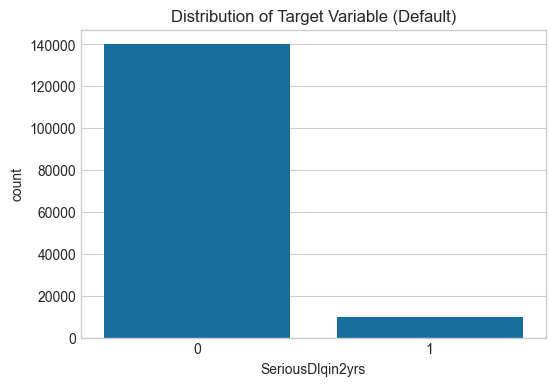

In [10]:
target = 'SeriousDlqin2yrs'

class_counts = df[target].value_counts()
class_props = df[target].value_counts(normalize=True) * 100

print(f"Good Loans (0): {class_counts[0]} ({class_props[0]:.2f}%)")
print(f"Defaulted Loans (1): {class_counts[1]} ({class_props[1]:.2f}%)")

# Visualize the imbalance
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target)
plt.title("Distribution of Target Variable (Default)")
plt.show()

# Missing Value Diagnostics

In [11]:
# Cell 5
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100

missing_df = pd.DataFrame({'Missing_Count': missing_data, 'Missing_Percent': missing_percent})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(by='Missing_Percent', ascending=False)

display(missing_df)

,Missing_Count,Missing_Percent
MonthlyIncome,29731,19.820667
NumberOfDependents,3924,2.616000


# Outlier Detection (Visualizing the Anomaly)

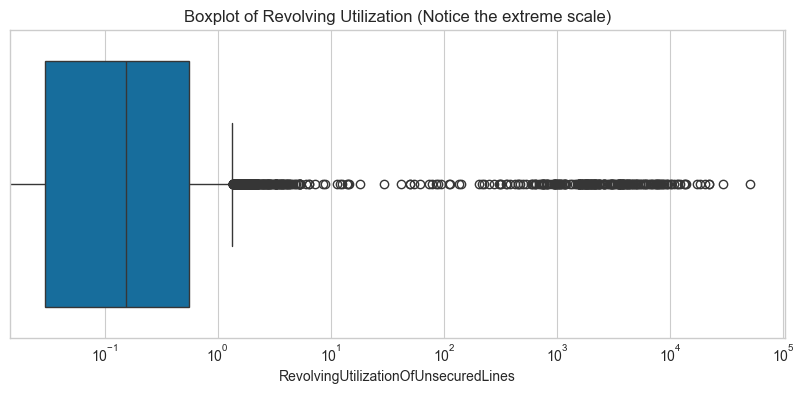

In [12]:
# Cell 6
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['RevolvingUtilizationOfUnsecuredLines'])
plt.title("Boxplot of Revolving Utilization (Notice the extreme scale)")
plt.xscale('log') # Log scale helps visualize extreme ranges
plt.show()